# Load data

In [1]:
import pandas as pd  

df = pd.read_csv("Salary_Data.csv")
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [2]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [6]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [5]:
df.nunique()

Age                     41
Gender                   3
Education Level          7
Job Title              193
Years of Experience     37
Salary                 444
dtype: int64

In [7]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [8]:
df.dropna(inplace=True)

In [10]:
edu_map = {
    "Bachelor's Degree": "Bachelor's",
    "Bachelor's": "Bachelor's",
    "Master's Degree": "Master's",
    "Master's": "Master's",
    "PhD": "PhD",
    "phD": "PhD",
    "High School": "High School"
}
df['Education Level'] = df['Education Level'].map(edu_map)

In [14]:
col = "Job Title"
threshold = 5  # 5'ten az geçen sınıflar "rare"

counts = df[col].value_counts()
rare = counts[counts < threshold]

rare_classes = rare.index.astype(object)
rare_df = rare.rename_axis(col).reset_index(name="count")

In [15]:
rare_df.describe()

,count
count,117.000000
mean,1.495726
std,0.847145
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [16]:
df['Job Title'] = df['Job Title'].apply(lambda x: 'Other' if x in rare_classes else x)

In [17]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Other,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Other,20.0,200000.0


In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

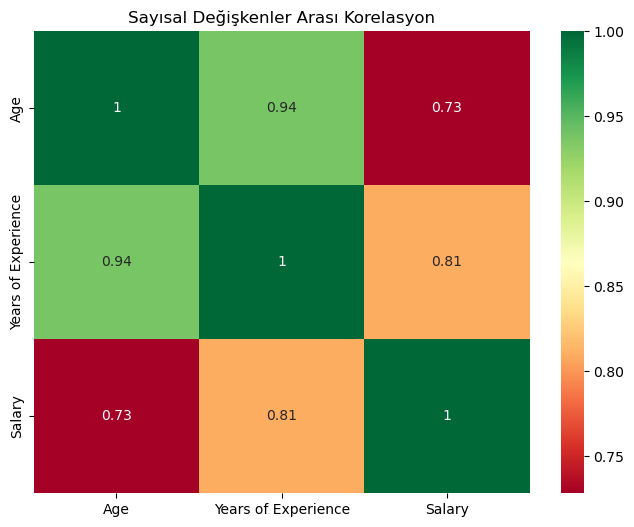

In [20]:
# 1. Isı Haritası (Sadece sayısal sütunlar)
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap="RdYlGn")
plt.title("Sayısal Değişkenler Arası Korelasyon")
plt.show()

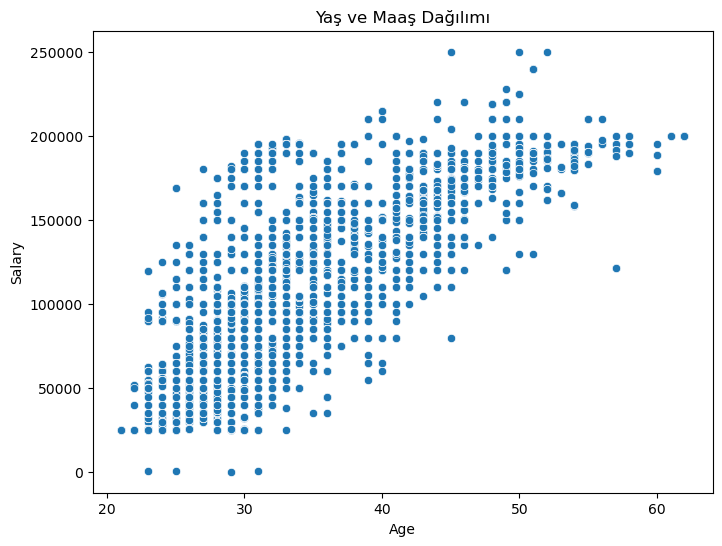

In [21]:
# 2. Scatter Plot (Yaş ve Maaş Dağılımı)
plt.figure(figsize=(8, 6))
sns.scatterplot(x="Age", y="Salary", data=df)
plt.title("Yaş ve Maaş Dağılımı")
plt.show()

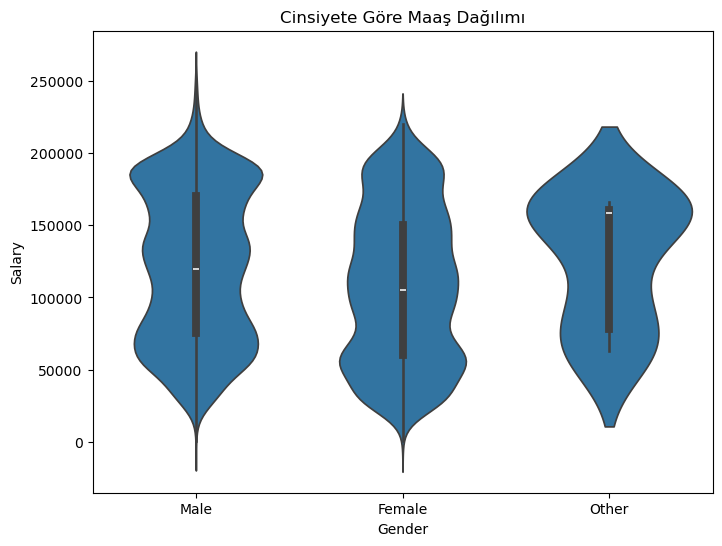

In [22]:
# 3. Violin Plot (Cinsiyete Göre Maaş Dağılımı)
plt.figure(figsize=(8, 6))
sns.violinplot(x="Gender", y="Salary", data=df)
plt.title("Cinsiyete Göre Maaş Dağılımı")
plt.show()

In [53]:
# String ifadeleri 0 ve 1'lere çevirme (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['Gender', 'Education Level', 'Job Title'], drop_first=True)

print("İşlem sonrası makineye verilecek toplam sütun sayısı:", df_encoded.shape[1])
display(df_encoded.head())

İşlem sonrası makineye verilecek toplam sütun sayısı: 82


,Age,Years of Experience,Salary,Gender_Male,Gender_Other,Education Level_High School,Education Level_Master's,Education Level_PhD,Job Title_Content Marketing Manager,Job Title_Customer Service Representative,...,Job Title_Senior Project Coordinator,Job Title_Senior Project Engineer,Job Title_Senior Project Manager,Job Title_Senior Research Scientist,Job Title_Senior Software Engineer,Job Title_Social Media Manager,Job Title_Software Developer,Job Title_Software Engineer,Job Title_Software Engineer Manager,Job Title_Web Developer
0,32.0,5.0,90000.0,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,28.0,3.0,65000.0,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,45.0,15.0,150000.0,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
3,36.0,7.0,60000.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,52.0,20.0,200000.0,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [54]:
# Sınırları belirleme (IQR hesaplama)
q1 = df_encoded["Salary"].quantile(0.25)
q3 = df_encoded["Salary"].quantile(0.75)
iqr = q3 - q1
threshold = 1.5 * iqr
lower_bound = q1 - threshold
upper_bound = q3 + threshold

In [55]:
# Aykırı değerleri filtreleyip temizleme
df_encoded = df_encoded[(df_encoded["Salary"] >= lower_bound) & (df_encoded["Salary"] <= upper_bound)]

print("Aykırı değerler temizlendikten sonra kalan satır sayısı:", df_encoded.shape[0])

Aykırı değerler temizlendikten sonra kalan satır sayısı: 6698


In [30]:
df.head()



,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Other,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Other,20.0,200000.0


In [31]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=["Salary"])
y = df_encoded["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Eğitim seti boyutu:", X_train.shape)

Eğitim seti boyutu: (5358, 81)


In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [33]:
X

,Age,Years of Experience,Gender_Male,Gender_Other,Education Level_High School,Education Level_Master's,Education Level_PhD,Job Title_Content Marketing Manager,Job Title_Customer Service Representative,Job Title_Data Analyst,...,Job Title_Senior Project Coordinator,Job Title_Senior Project Engineer,Job Title_Senior Project Manager,Job Title_Senior Research Scientist,Job Title_Senior Software Engineer,Job Title_Social Media Manager,Job Title_Software Developer,Job Title_Software Engineer,Job Title_Software Engineer Manager,Job Title_Web Developer
0,32.0,5.0,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,28.0,3.0,False,False,False,True,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
2,45.0,15.0,True,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,36.0,7.0,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,52.0,20.0,True,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6699,49.0,20.0,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6700,32.0,3.0,True,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6701,30.0,4.0,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6702,46.0,14.0,True,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [28]:
X_train

array([[ 0.89507087,  0.79000963,  0.68633278,  0.3157382 ],
       [-1.09736357,  0.79000963, -1.57390402,  0.3157382 ],
       [-1.09736357,  1.34001893,  0.30962665,  0.64806809],
       ...,
       [ 0.89507087, -0.86001828, -0.13557151, -1.17974629],
       [ 0.89507087, -0.86001828, -0.13557151, -1.17974629],
       [-1.09736357, -1.41002758, -1.31705893, -1.01358135]],
      shape=(5358, 4))

In [45]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Modeli kurma ve eğitme
rf_model = RandomForestRegressor(random_state=42, n_estimators=100)
rf_model.fit(X_train, y_train)

# Test verisi üzerinden tahmin yapma
y_pred = rf_model.predict(X_test)

# Sonuçlar ve Başarı Skorları
print("R2 Skoru (Başarı Oranı):", r2_score(y_test, y_pred))
print("Ortalama Mutlak Hata (MAE):", mean_absolute_error(y_test, y_pred))

R2 Skoru (Başarı Oranı): 0.9742933021574149
Ortalama Mutlak Hata (MAE): 3316.714619399623


In [47]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Değerleri hesaplatıyoruz
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Ekranda alt alta yazdırma komutları
print("Ortalama Kare Hata (MSE):", mse)
print("Ortalama Mutlak Hata (MAE):", mae)
print("R2 Skoru (Başarı Oranı):", r2)

Ortalama Kare Hata (MSE): 73301601.31307662
Ortalama Mutlak Hata (MAE): 3316.714619399623
R2 Skoru (Başarı Oranı): 0.9742933021574149


In [48]:
X_test

array([[ 0.31229255,  0.14957326,  0.91134144, ..., -0.29277002,
        -0.24738682, -0.11421884],
       [-0.8728315 , -0.68125146, -1.09728358, ..., -0.29277002,
        -0.24738682, -0.11421884],
       [-1.1361924 , -1.17974629, -1.09728358, ..., -0.29277002,
        -0.24738682, -0.11421884],
       ...,
       [-0.74115105, -0.34892157, -1.09728358, ..., -0.29277002,
        -0.24738682, -0.11421884],
       [ 0.7073339 ,  0.3157382 , -1.09728358, ..., -0.29277002,
        -0.24738682, -0.11421884],
       [-1.00451195, -0.84741641,  0.91134144, ..., -0.29277002,
        -0.24738682, -0.11421884]])

In [49]:
mse

73301601.31307662

In [50]:
mae

3316.714619399623

In [51]:
r2

0.9742933021574149